# Neural Machine Translation with Attention (English → German)

A sequence-to-sequence translation model built in PyTorch: first a GRU encoder–decoder, then the same model with additive (Bahdanau) attention. Both are trained on [Multi30k](https://huggingface.co/datasets/bentrevett/multi30k) (~29k English–German image-caption pairs), followed by an analysis of the model's translation errors and attention patterns.

| Model | Test BLEU |
|---|---|
| GRU encoder–decoder | 14.0 |
| GRU encoder–decoder + additive attention | **24.2** |

**About this notebook:** it started from a university NLP course template, which provided the data pipeline, model skeletons, BLEU evaluation and plotting helpers. I implemented the decoder step, the masked training loss, the training loop, the attention layer, the attentive model and attention extraction (code marked `### MY CODE`), and wrote all of the analysis. The models were trained on a T4 GPU in Google Colab.

![Encoder-decoder diagram](https://lena-voita.github.io/resources/lectures/seq2seq/general/enc_dec_simple_rnn-min.png)

*Diagram: [Lena Voita, NLP Course For You](https://lena-voita.github.io/nlp_course/seq2seq_and_attention.html)*

## Setup

In [4]:
# install dependencies
!pip3 install torch pandas nltk matplotlib
!pip3 install subword-nmt &> log
!wget https://gist.githubusercontent.com/saparina/45e4e8af5cb6b57c786ca246e1c75530/raw/b7d06c8a570b68ef22c9fc2f627bbb8a54f4cf27/vocab.py

In [5]:
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

%matplotlib inline

In [6]:
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [7]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [8]:
source_lang = "en"
target_lang = "de"
splits = ['train', 'val', 'test']

data = {}
for split in splits:
    file_name = f"{split}.jsonl"
    df = pd.read_json(f"hf://datasets/bentrevett/multi30k/{file_name}", lines=True)
    data[split] = df

for split, df in data.items():
    df['de'].to_csv(f"{split}.de", index=False, header=False, mode='w')
    df['en'].to_csv(f"{split}.en", index=False, header=False, mode='w')

## 1. Data Preprocessing

The dataset has ~29k English–German sentence pairs for training, ~1k for validation and 1k for testing. Preprocessing:
1. Text is lowercased and tokenized with [WordPunctTokenizer](https://www.nltk.org/api/nltk.tokenize.regexp.html#nltk.tokenize.regexp.WordPunctTokenizer), which splits on word boundaries and punctuation.

2. [Byte Pair Encoding](https://github.com/rsennrich/subword-nmt) (8,000 merges per language) is applied on top. BPE starts from characters and repeatedly merges the most frequent pair, so frequent words end up as single tokens and rare words are split into subwords.

In [9]:
from nltk.tokenize import WordPunctTokenizer
from subword_nmt.learn_bpe import learn_bpe
from subword_nmt.apply_bpe import BPE
tokenizer = WordPunctTokenizer()
def tokenize(x):
    return ' '.join(tokenizer.tokenize(x.lower()))

# split and tokenize the data
for lang in [source_lang, target_lang]:
    for split in splits:
        with open(split + '.tok.' + lang, 'w') as f_src:
            for line in open(split + '.' + lang):
                f_src.write(tokenize(line) + '\n')

# build and apply bpe vocs
bpe = {}
for lang in [source_lang, target_lang]:
    learn_bpe(open('./train.tok.' + lang), open('bpe_rules.' + lang, 'w'), num_symbols=8000)
    bpe[lang] = BPE(open('./bpe_rules.' + lang))

    for split in splits:
        with open(split + '.bpe.' + lang, 'w') as f_out:
            for line in open(split + '.tok.' + lang):
                f_out.write(bpe[lang].process_line(line.strip()) + '\n')

100%|██████████| 8000/8000 [00:06<00:00, 1253.45it/s]


### Building vocabularies

Vocabularies map tokens to ids and back. They are used to feed training data into the model and to turn output matrices back into words.

In [10]:
train_inp = np.array(open('train.bpe.' + source_lang, encoding='utf-8').read().split('\n'))
train_out = np.array(open('train.bpe.' + target_lang, encoding='utf-8').read().split('\n'))

val_inp   = np.array(open('val.bpe.' + source_lang, encoding='utf-8').read().split('\n'))
val_out   = np.array(open('val.bpe.' + target_lang, encoding='utf-8').read().split('\n'))

test_inp = np.array(open('test.bpe.' + source_lang, encoding='utf-8').read().split('\n'))
test_out = np.array(open('test.bpe.' + target_lang, encoding='utf-8').read().split('\n'))

for i in range(3):
    print('inp:', train_inp[i])
    print('out:', train_out[i], end='\n\n')

inp: " two young , white males are outside near many bushes ."
out: zwei junge weiße männer sind im freien in der nähe viel@@ er büsche .

inp: several men in hard hats are operating a giant pulley system .
out: mehrere männer mit schutzhelmen bedienen ein an@@ tri@@ eb@@ s@@ rad@@ system .

inp: a little girl climbing into a wooden playhouse .
out: ein kleines mädchen klettert in ein spiel@@ haus aus holz .



In [11]:
from vocab import Vocab
inp_voc = Vocab.from_lines(train_inp)
out_voc = Vocab.from_lines(train_out)

print("Source vocab size", len(inp_voc))
print("Target vocab size", len(out_voc))

Source vocab size 7202
Target vocab size 7679


In [12]:
# Here's how you cast lines into ids and backwards.
batch_lines = sorted(train_inp, key=len)[5:10]
batch_ids = inp_voc.to_matrix(batch_lines)
batch_lines_restored = inp_voc.to_lines(batch_ids)

print("lines")
print(batch_lines)
print("\nwords to ids (0 = bos, 1 = eos):")
print(batch_ids)
print("\nback to words")
print(batch_lines_restored)

lines
[np.str_('men play baseball .'), np.str_('a child in a swing .'), np.str_('a man playing cricket'), np.str_('a car is in the water'), np.str_('a man climbs a rock .')]

words to ids (0 = bos, 1 = eos):
tensor([[   0, 3659, 4416,  544,   22,    1,    1,    1],
        [   0,   65, 1166, 2969,   65, 6002,   22,    1],
        [   0,   65, 3568, 4424, 1513,    1,    1,    1],
        [   0,   65, 1010, 3065, 2969, 6186, 6902,    1],
        [   0,   65, 3568, 1255,   65, 4901,   22,    1]])

back to words
['men play baseball .', 'a child in a swing .', 'a man playing cricket', 'a car is in the water', 'a man climbs a rock .']


Source and translation length distributions (in BPE tokens):

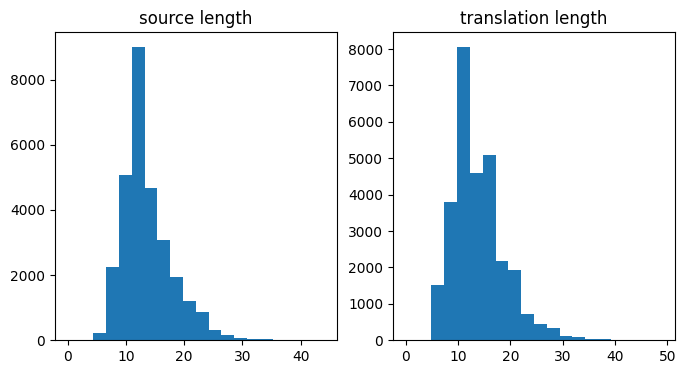

In [13]:
plt.figure(figsize=[8, 4])
plt.subplot(1, 2, 1)
plt.title("source length")
plt.hist(list(map(len, map(str.split, train_inp))), bins=20);

plt.subplot(1, 2, 2)
plt.title("translation length")
plt.hist(list(map(len, map(str.split, train_out))), bins=20);

### Special tokens: BOS and EOS

*What do indices 0 and 1 in the vocabulary represent, what role do they play in the model, and could it be trained without them?*

Index 0 is BOS (beginning of sequence) and index 1 is EOS (end of sequence). In the probabilistic model, BOS is the initial input token given to the decoder at the first time step. The model predicts EOS when the output is complete, and EOS is also used as the padding token, so the loss mask can ignore positions beyond the end of the sequence. It's possible to train a model without them: without BOS, we can initialize the decoder directly from the encoder's final hidden state and use a learned bias vector as the first input, and without EOS we can predict fixed-length outputs.

### Observations on BPE subword tokenization

*What patterns show up in the BPE-tokenized sentences?*

First, BPE splits complex and less frequent words into smaller subwords marked with `@@`. For example, `viel@@ er` and `spiel@@ haus` are each split into two subwords, and `an@@ tri@@ eb@@ s@@ rad@@ system` breaks a long German compound into several subwords. Short or common words remain intact.

Second, the splits tend to follow meaningful parts of words, especially in German compounds. For example, `spiel@@ haus` corresponds to the compound "playhouse" (spiel = play, haus = house), and the long form `an@@ tri@@ eb@@ s@@ rad@@ system` is segmented into internal components rather than random character fragments. This shows BPE is capturing some morphological structure, which is useful for a language like German where compounding is very common.

## 2. Basic Encoder-Decoder Model

A simple encoder–decoder model: a single GRU encoder and a GRU decoder, with no attention. I implemented `decode_step`; the rest of the class was provided.

In [14]:
class BasicModel(nn.Module):
    def __init__(self, inp_voc, out_voc, emb_size=64, hid_size=128):
        """
        A simple encoder-decoder seq2seq model
        """
        super().__init__() # initialize base class to track sub-layers, parameters, etc.

        self.inp_voc, self.out_voc = inp_voc, out_voc
        self.hid_size = hid_size

        self.emb_inp = nn.Embedding(len(inp_voc), emb_size)
        self.emb_out = nn.Embedding(len(out_voc), emb_size)
        self.enc0 = nn.GRU(emb_size, hid_size, batch_first=True)

        self.dec_start = nn.Linear(hid_size, hid_size)
        self.dec0 = nn.GRUCell(emb_size, hid_size)
        self.logits = nn.Linear(hid_size, len(out_voc))

    def forward(self, inp, out):
        """ Apply model in training mode """
        initial_state = self.encode(inp)
        return self.decode(initial_state, out)


    def encode(self, inp, **flags):
        """
        Takes symbolic input sequence, computes initial state
        :param inp: matrix of input tokens [batch, time]
        :returns: initial decoder state tensors, one or many
        """
        # compute embeddings
        inp_emb = self.emb_inp(inp)
        batch_size = inp.shape[0]

        # sequentially applying a GRU cell to each input
        # (this logic is hidden in the GRU implementation)
        enc_seq, [last_state_but_not_really] = self.enc0(inp_emb)
        # enc_seq: [batch, time, hid_size], last_state: [batch, hid_size]

        # note: enc0 works on a batch level, so we will need to process padding!
        # last_state is not _actually_ last because of padding, let's find the real last_state
        lengths = (inp != self.inp_voc.eos_ix).to(torch.int64).sum(dim=1).clamp_max(inp.shape[1] - 1)
        last_state = enc_seq[torch.arange(len(enc_seq)), lengths]
        # ^-- shape: [batch_size, hid_size]

        # create an initial hidden vector for the decoder
        dec_start = self.dec_start(last_state)
        return [dec_start]

    def decode_step(self, prev_state, prev_tokens, **flags):
        """
        Takes previous decoder state and tokens, returns new state and logits for next tokens
        :param prev_state: a list of previous decoder state tensors, same as returned by encode(...)
        :param prev_tokens: previous output tokens, an int vector of [batch_size]
        :return: a list of next decoder state tensors, a tensor of logits [batch, len(out_voc)]
        """
        prev_gru0_state = prev_state[0]

        ### MY CODE
        prev_tokens_emb = self.emb_out(prev_tokens) #get embedding of previous tokens
        new_dec_state = self.dec0(prev_tokens_emb, prev_gru0_state) #apply decoder rnn cell
        output_logits = self.logits(new_dec_state) #get logits

        return [new_dec_state], output_logits

    def decode(self, initial_state, out_tokens, **flags):
        """ Iterate over reference tokens (out_tokens) with decode_step, use for training"""
        batch_size = out_tokens.shape[0]
        state = initial_state

        # initial logits: always predict BOS
        onehot_bos = F.one_hot(torch.full([batch_size], self.out_voc.bos_ix, dtype=torch.int64),
                               num_classes=len(self.out_voc)).to(device=out_tokens.device)
        first_logits = torch.log(onehot_bos.to(torch.float32) + 1e-9)

        logits_sequence = [first_logits]
        for i in range(out_tokens.shape[1] - 1):
            # note: we use the reference labels here (out_tokens)
            state, logits = self.decode_step(state, out_tokens[:, i])
            logits_sequence.append(logits)
        return torch.stack(logits_sequence, dim=1)

    def decode_inference(self, initial_state, max_len=100, **flags):
        """ Generate translations from model (greedy version), use for inference """
        batch_size, device = len(initial_state[0]), initial_state[0].device
        state = initial_state
        outputs = [torch.full([batch_size], self.out_voc.bos_ix, dtype=torch.int64,
                              device=device)]
        all_states = [initial_state]

        for i in range(max_len):
            # note: we use the predicted tokens
            state, logits = self.decode_step(state, outputs[-1])
            outputs.append(logits.argmax(dim=-1))
            all_states.append(state)

        return torch.stack(outputs, dim=1), all_states

    def translate_lines(self, inp_lines, **kwargs):
        inp = self.inp_voc.to_matrix(inp_lines).to(device)
        initial_state = self.encode(inp)
        out_ids, states = self.decode_inference(initial_state, **kwargs)
        return self.out_voc.to_lines(out_ids.cpu().numpy()), states

In [15]:
# debugging area
model = BasicModel(inp_voc, out_voc).to(device)

dummy_inp_tokens = inp_voc.to_matrix(sorted(train_inp, key=len)[5:10]).to(device)
dummy_out_tokens = out_voc.to_matrix(sorted(train_out, key=len)[5:10]).to(device)

h0 = model.encode(dummy_inp_tokens)
h1, logits1 = model.decode_step(h0, torch.arange(len(dummy_inp_tokens), device=device))

assert isinstance(h1, list), type(h1)
assert len(h1) == len(h0)
assert h1[0].shape == h0[0].shape and not torch.allclose(h1[0], h0[0])
assert logits1.shape == (len(dummy_inp_tokens), len(out_voc))

logits_seq = model.decode(h0, dummy_out_tokens)
assert logits_seq.shape == (dummy_out_tokens.shape[0], dummy_out_tokens.shape[1], len(out_voc))

# full forward
logits_seq2 = model(dummy_inp_tokens, dummy_out_tokens)
assert logits_seq2.shape == logits_seq.shape

In [16]:
dummy_translations, dummy_states = model.translate_lines(train_inp[:3], max_len=25)
print("Translations without training:")
print('\n'.join([line for line in dummy_translations]))

Translations without training:
afri@@ fußgängerbrücke teenagerin musku@@ football@@ pfeil orche@@ stie@@ y lackiert lackiert pre@@ afroamerikan@@ dribbelt stellt tzt winterjacke sportlerin ron stift aufhat trainieren etwas schrif@@ gür@@
afri@@ tte richter richter repariert vorbei ” suchen haltung verkehrt ara@@ trüben alls spielend akkordeon@@ packen steu@@ noti@@ lö@@ pustet übung neben@@ coca ehnt promenade
afri@@ wildwasser@@ 8@@ schleife rennt schnau@@ telef@@ telef@@ gegend hier ganzen oberteilen felsbrocken tro@@ handschuhe lächelndes 4@@ hemd@@ anzüge babyschaukel unterhaltung kreide koch@@ tanzfläche skolben


### Training loss

Our training objective is:
$$ L = {\frac1{|D|}} \sum_{X, Y \in D} \sum_{y_t \in Y} - \log p(y_t \mid y_1, \dots, y_{t-1}, X, \theta) $$

where $|D|$ is the __total length of all sequences__, including BOS and first EOS, but excluding PAD. `compute_loss` implements this as masked token-level cross-entropy.

In [17]:

def compute_loss(model, inp, out, **flags):
    """
    Compute loss (float32 scalar) as in the formula above
    :param inp: input tokens matrix, int32[batch, time]
    :param out: reference tokens matrix, int32[batch, time]

    In order to pass the tests, your function should
    * include loss at first EOS but not the subsequent ones
    * divide sum of losses by a sum of input lengths (use voc.compute_mask)
    """
    mask = model.out_voc.compute_mask(out) # [batch_size, out_len]
    targets_1hot = F.one_hot(out, len(model.out_voc)).to(torch.float32)

    # outputs of the model, [batch_size, out_len, num_tokens]
    outputs = model(inp, out)

    # log-probabilities of all tokens at all steps, [batch_size, out_len, num_tokens]
    log_probs = F.log_softmax(outputs, dim=-1)

    # log-probabilities of correct outputs, [batch_size, out_len]
    target_log_probs = (log_probs * targets_1hot).sum(dim=-1) #selects the probability of the actual next token.


    # average cross-entropy over tokens where mask == True
    mask = mask.to(log_probs.dtype)
    loss = -(target_log_probs * mask).sum() / mask.sum()
    return loss

In [18]:
dummy_loss = compute_loss(model, dummy_inp_tokens, dummy_out_tokens)
print("Loss:", dummy_loss)
assert np.allclose(dummy_loss.item(), 7.6, rtol=0.01, atol=0.01), "We're sorry for your loss"

# test autograd
dummy_loss.backward()
for name, param in model.named_parameters():
    assert param.grad is not None and abs(param.grad.max()) != 0, f"Param {name} received no gradients"

print("Test passed!")

Loss: tensor(7.6071, device='cuda:0', grad_fn=<DivBackward0>)
Test passed!


### Evaluation: BLEU

Machine translation is commonly evaluated with [BLEU](https://en.wikipedia.org/wiki/BLEU) score. This metric simply computes which fraction of predicted n-grams is actually present in the reference translation. It does so for n=1,2,3 and 4 and computes the geometric average with penalty if translation is shorter than reference.

In [19]:
from nltk.translate.bleu_score import corpus_bleu
def compute_bleu(model, inp_lines, out_lines, bpe_sep='@@ ', **flags):
    """
    Estimates corpora-level BLEU score of model's translations given inp and reference out
    Note: if you're serious about reporting your results, use https://pypi.org/project/sacrebleu
    """
    with torch.no_grad():
        translations, _ = model.translate_lines(inp_lines, **flags)
        translations = [line.replace(bpe_sep, '') for line in translations]
        actual = [line.replace(bpe_sep, '') for line in out_lines]
        return corpus_bleu(
            [[ref.split()] for ref in actual],
            [trans.split() for trans in translations],
            smoothing_function=lambda precisions, **kw: [p + 1.0 / p.denominator for p in precisions]
            ) * 100

In [20]:
compute_bleu(model, val_inp, val_out)

0.004044872108229374

### Training loop

Training an encoder–decoder model works like training any other model: sample batches, compute the loss, backpropagate and update.

In [21]:
from IPython.display import clear_output
from tqdm import tqdm, trange

model = BasicModel(inp_voc, out_voc).to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
batch_size = 32

In [22]:
print("Model size", sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6, "M")

Model size 2.108479 M


The training loop runs 20k steps with Adam (lr 1e-3, batch size 32), evaluates validation BLEU every 100 steps and keeps the best checkpoint:

In [23]:
def train(model, opt, batch_size, num_steps=20000, save_path="best_basemodel.pth"):
    metrics = {'train_loss': [], 'dev_bleu': [] }
    best_bleu = 0.0
    for _ in trange(num_steps):
        step = len(metrics['train_loss']) + 1
        batch_ix = np.random.randint(len(train_inp), size=batch_size)
        batch_inp = inp_voc.to_matrix(train_inp[batch_ix]).to(device)
        batch_out = out_voc.to_matrix(train_out[batch_ix]).to(device)

        ### MY CODE
        loss_t = compute_loss(model, batch_inp, batch_out)
        opt.zero_grad()
        loss_t.backward()
        opt.step()
        ### END OF MY CODE

        metrics['train_loss'].append((step, loss_t.item()))

        if step % 100 == 0:
            dev_bleu = compute_bleu(model, val_inp, val_out)
            metrics['dev_bleu'].append((step, dev_bleu))

            if dev_bleu > best_bleu:
                best_bleu = dev_bleu
                torch.save(model.state_dict(), save_path)

            clear_output(True)
            plt.figure(figsize=(12,4))
            for i, (name, history) in enumerate(sorted(metrics.items())):
                plt.subplot(1, len(metrics), i + 1)
                plt.title(name)
                plt.plot(*zip(*history))
                plt.grid()
            plt.show()
            print("Mean loss=%.3f" % np.mean(metrics['train_loss'][-10:], axis=0)[1], flush=True)
    return metrics

Train the basic model (~10 minutes on a T4 GPU):

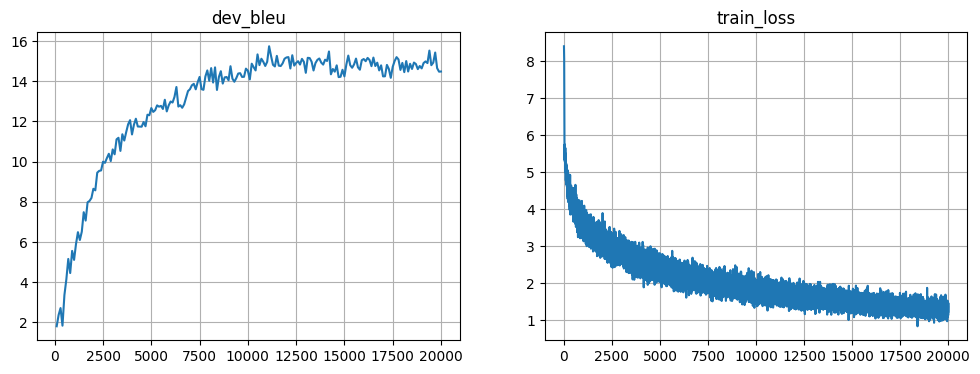

Mean loss=1.325


100%|██████████| 20000/20000 [10:22<00:00, 32.12it/s]


In [25]:
metrics = train(model, opt, batch_size)
# Note: it's okay if bleu oscillates up and down as long as it gets better on average over long term (e.g. 5k batches)

In [26]:
bleu_scores = np.mean(metrics['dev_bleu'][-10:], axis=0)[1]
assert bleu_scores > 13, f"BLEU score should be > 13 on average, you got {bleu_scores}"

In [27]:
model.load_state_dict(torch.load("best_basemodel.pth", weights_only=True))
model.to(device)

final_bleu_score = compute_bleu(model, test_inp, test_out)
f"BLEU score on the test set: {final_bleu_score:.3}"

'BLEU score on the test set: 14.0'

## 3. Encoder-Decoder Model with Attention

Next, the basic model is extended with additive attention, in two parts: the __attention layer__ and an __attentive seq2seq model__ that uses it.

### Attention layer

The layer computes additive attention:

Given encoder sequence $ h^e_0, h^e_1, h^e_2, ..., h^e_T$ and a single decoder state $h^d$,

* Compute scores with a 2-layer neural network:
$$s_t = \operatorname{linear}_{out}(\tanh(\operatorname{linear}_{enc}(h^e_t) + \operatorname{linear}_{dec}(h^d)))$$
* Get probabilities from scores:
$$ p_t = {{e ^ {s_t}} \over { \sum_\tau e^{s_\tau} }} $$

* Add up encoder states with probabilities to get __attention response__ (attention context vector):
$$ c = \sum_t p_t \cdot h^e_t $$

In [ ]:
class AttentionLayer(nn.Module):
    def __init__(self, name, enc_size, dec_size, hid_size, activ=torch.tanh):
        """ A layer that computes additive attention response and weights """
        super().__init__()
        self.name = name
        self.enc_size = enc_size # num units in encoder state
        self.dec_size = dec_size # num units in decoder state
        self.hid_size = hid_size # attention layer hidden units
        self.activ = activ       # attention layer hidden nonlinearity

        # create trainable paramteres
        self.linear_enc = nn.Parameter(torch.zeros(self.enc_size, self.hid_size), requires_grad=True)
        self.linear_dec = nn.Parameter(torch.zeros(self.dec_size, self.hid_size), requires_grad=True) # you will need a couple of these
        self.linear_out = nn.Parameter(torch.zeros(self.hid_size, 1), requires_grad=True)

        torch.nn.init.xavier_uniform_(self.linear_enc.data)
        torch.nn.init.xavier_uniform_(self.linear_dec.data)
        torch.nn.init.xavier_uniform_(self.linear_out.data)


    def forward(self, enc, dec, inp_mask):
        """
        Computes attention response and weights
        :param enc: encoder activation sequence, float32[batch_size, ninp, enc_size]
        :param dec: single decoder state used as "query", float32[batch_size, dec_size]
        :param inp_mask: mask on enc activatons (0 after first eos), float32 [batch_size, ninp]
        :returns: attn[batch_size, enc_size], probs[batch_size, ninp]
            - attn - attention response vector (weighted sum of enc)
            - probs - attention weights after softmax
        """
        # Compute scores
        ### MY CODE
        enc_proj = enc @ self.linear_enc                          # [batch_size, ninp, hid_size]
        dec_proj = (dec @ self.linear_dec).unsqueeze(1)           # [batch_size, 1, hid_size]
        scores = (self.activ(enc_proj + dec_proj) @ self.linear_out).squeeze(-1) # [batch_size, ninp, 1]

        # Apply mask - if mask is 0, scores should be -inf or -1e9
        # You may need torch.where
        scores = torch.where(inp_mask > 0, scores, torch.full_like(scores, -1e9))

        # Compute attention probabilities (softmax)
        probs = F.softmax(scores, dim=1)

        # Compute attention response using enc and probs
        attn = (probs.unsqueeze(-1) * enc).sum(dim=1)
        ### END OF MY CODE

        return attn, probs

In [29]:
# debugging
batch_size = 32
ninp = 7
enc_size = 64
dec_size = 128
layer = AttentionLayer("", enc_size, dec_size, 72)
attn, probs = layer(torch.rand(batch_size, ninp, enc_size), torch.rand(batch_size, dec_size), torch.rand(batch_size, ninp) > .5)
assert attn.shape == (batch_size, enc_size), attn.shape
assert probs.shape == (batch_size, ninp), probs.shape # if you have redundant dimensions of size 1, you might find torch.squeeze useful

### Seq2seq model with attention

Attention is used in the decoder:

![Bahdanau attention diagram](https://lena-voita.github.io/resources/lectures/seq2seq/attention/bahdanau_model-min.png)

*Diagram: [Lena Voita, NLP Course For You](https://lena-voita.github.io/nlp_course/seq2seq_and_attention.html)*

- At every step, the __previous__ decoder state is used as the query to get an attention response over the encoder outputs.
- That response is concatenated with the previous token's embedding and fed to the decoder GRU.

The key implementation detail is the __model state__: every tensor returned by `encode` is available at each `decode_step`. The state holds:
* the decoder's recurrent hidden state (as in the basic model)
* the full sequence of encoder outputs (to attend to) and its padding mask
* the attention response and attention probabilities (kept for visualization)

In [30]:
class AttentiveModel(BasicModel):
    def __init__(self, name, inp_voc, out_voc,
                 emb_size=64, hid_size=128, attn_size=128):
        """ Translation model that uses attention. Inherit all functions and params of BasicModel """
        self.inp_voc, self.out_voc = inp_voc, out_voc
        self.hid_size = hid_size

        super().__init__(inp_voc, out_voc, emb_size=emb_size, hid_size=hid_size)
        self.attention = AttentionLayer(name, hid_size, hid_size, attn_size)
        self.dec0 = nn.GRUCell(emb_size + attn_size, hid_size)

    def encode(self, inp, **flags):
        """
        Takes symbolic input sequence, computes initial state
        :param inp: matrix of input tokens [batch, time]
        :return: a list of initial decoder state tensors
        """
        # encode input sequence, create initial decoder states
        ### MY CODE
        inp_emb = self.emb_inp(inp)

        enc_seq, [last_state_but_not_really] = self.enc0(inp_emb)
        # enc_seq: [batch, time, hid_size], last_state: [batch, hid_size]
        ### END OF MY CODE

        # note: last_state is not _actually_ last because of padding, let's find the real last_state
        lengths = (inp != self.inp_voc.eos_ix).to(torch.int64).sum(dim=1).clamp_max(inp.shape[1] - 1)
        last_state = enc_seq[torch.arange(len(enc_seq)), lengths]
        # ^-- shape: [batch_size, hid_size]

        dec_start = self.dec_start(last_state)

        # apply attention layer from initial decoder hidden state
        inp_mask = self.inp_voc.compute_mask(inp)

        ### MY CODE
        first_attn_response, first_attn_probas = self.attention(enc_seq, dec_start, inp_mask)
        ### END OF MY CODE

        # Build first state: include
        # * initial states for decoder recurrent layers
        # * encoder sequence and encoder attn mask (for attention)
        # * make sure that last state item is attention probabilities tensor

        first_state = [dec_start, enc_seq, inp_mask, first_attn_response, first_attn_probas]
        return first_state

    def decode_step(self, prev_state, prev_tokens, **flags):
        """
        Takes previous decoder state and tokens, returns new state and logits for next tokens
        :param prev_state: a list of previous decoder state tensors
        :param prev_tokens: previous output tokens, an int vector of [batch_size]
        :return: a list of next decoder state tensors, a tensor of logits [batch, n_tokens]
        """
        prev_gru0_state, enc_seq, inp_mask, prev_attn_response, prev_attn_probas = prev_state

        ### MY CODE
        prev_tokens_emb = self.emb_out(prev_tokens)
        concat_inp = torch.cat([prev_tokens_emb, prev_attn_response], dim=-1)
        new_dec_state = self.dec0(concat_inp, prev_gru0_state)
        output_logits = self.logits(new_dec_state)

        attn_response, attn_probas = self.attention(enc_seq, new_dec_state, inp_mask)
        ### END OF MY CODE

        return [new_dec_state, enc_seq, inp_mask, attn_response, attn_probas], output_logits


### Training the attentive model

Same training loop and hyperparameters as the basic model (~21 minutes on a T4 GPU).

In [31]:
metrics = {'train_loss': [], 'dev_bleu': [] }

model = AttentiveModel("model", inp_voc, out_voc, hid_size=128, attn_size=128).to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
batch_size = 32

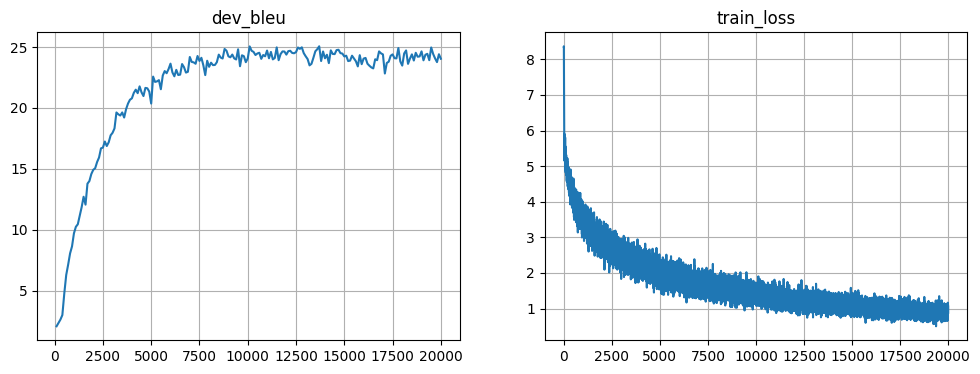

Mean loss=0.934


100%|██████████| 20000/20000 [21:07<00:00, 15.78it/s]


In [32]:
metrics = train(model, opt, batch_size, save_path="best_attentivemodel.pth")

In [33]:
model.load_state_dict(torch.load("best_attentivemodel.pth", weights_only=True))
model.to(device)

final_bleu_score = compute_bleu(model, test_inp, test_out)
f"BLEU score on the test set: {final_bleu_score:.3}"

'BLEU score on the test set: 24.2'

### Basic vs. attentive model

*Which model performs better, and why?*

The attentive model has a BLEU score of 24.2 and the basic model has a score of 14.0, so the attentive model performs much better. This is because with attention the decoder can focus on the important tokens at each generation step instead of relying on one fixed encoder summary vector. As a result, it preserves important details in longer or more complex sentences and improves translation quality.

## 4. Analysis

### Translations

The attentive model's translations of the first 5 test sentences:

In [34]:
for inp_line in test_inp[:5]:
    trans_line = model.translate_lines([inp_line])[0][0]
    print(inp_line)
    print(trans_line)
    print()

a man in an orange hat starring at something .
ein mann mit orangefarbener weste lächelt etwas an .

a boston terrier is running on lush green grass in front of a white fence .
ein dünn@@ ch@@ spieler rennt vor einem weißen zaun .

a girl in karate uniform breaking a stick with a front kick .
ein mädchen in karateanzügen ist mit einem gehstock an einem seil fest .

" five people wearing winter jackets and helmets stand in the snow , with snow@@ mobil@@ es in the background ."
fünf menschen in wintermänteln - röcken und mit helmen stehen im schnee und mit regenschirmen im hintergrund .

people are fixing the roof of a house .
leute fahren auf dem dach eines hauses .



### Error analysis

*What errors does the model make, and are there patterns?*

The model makes several consistent errors. It often swaps verbs or nouns for different ones that fit the scene, for example `hat` → `weste` (vest), `fixing` → `fahren` (riding), and `snow mobiles` → `regenschirmen` (umbrellas). Another issue is fragmented subword output: the model sometimes strings BPE pieces together into words that don't exist, such as `dünn@@ ch@@ spieler` for "boston terrier". A third problem is dropped details, such as `on lush green grass`.

### Possible improvements

*What changes might improve these translations?*

To improve the model, I would use early stopping on dev BLEU, because the score peaks around 25 and then declines, which indicates overfitting. To reduce verb/noun substitutions such as `hat → weste` and `fixing → fahren`, I would increase embedding capacity and train with more diverse examples so the model learns more reliable lexical mappings. I would also improve the decoding strategy, since some outputs hallucinate scene details that are not in the source sentence. Finally, I would retune the BPE vocabulary for German compounds so subwords are segmented more consistently and the output is less fragmented.

### Visualizing attention

Attention maps for the same 5 sentences (rows: German output tokens, columns: English source tokens). The plotting function was provided; I extracted the attention probabilities from the decoder states.

In [35]:
import matplotlib.pyplot as plt
import numpy as np

def draw_attention(inp_line, translation, probs):
    """ Visualize attention weights with a black background and white squares """
    # Tokenize input and translation
    inp_tokens = inp_voc.tokenize(inp_line)
    trans_tokens = out_voc.tokenize(translation)[1:]
    probs = probs[:len(trans_tokens), :len(inp_tokens)]

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.set_facecolor("black")
    cax = ax.matshow(probs, cmap='gray')

    color_bar = fig.colorbar(cax, ax=ax, orientation='vertical', fraction=0.046, pad=0.04)

    ax.set_xticks(np.arange(len(inp_tokens)))
    ax.set_xticklabels(inp_tokens, rotation=45, ha='left', rotation_mode='anchor')

    ax.set_yticks(np.arange(len(trans_tokens)))
    ax.set_yticklabels(trans_tokens)


    ax.tick_params(axis='both', which='both', length=0)
    ax.spines[:].set_visible(False)

    plt.show()

In [36]:
trans, states = model.translate_lines(test_inp[:5])

# select attention probs from model state
# attention_probs below must have shape [batch_size, translation_length, input_length], extracted from states
# e.g. if attention probs are at the end of each state, use np.stack([state[-1] for state in states], axis=1)

### MY CODE
attention_probs = np.stack([state[-1].detach().cpu().numpy() for state in states], axis=1)
### END OF MY CODE

In [37]:
# Check for all examples and all translation steps
assert np.allclose(attention_probs.sum(axis=2), 1.0, atol=1e-4), "Attention probabilities do not sum to 1!"

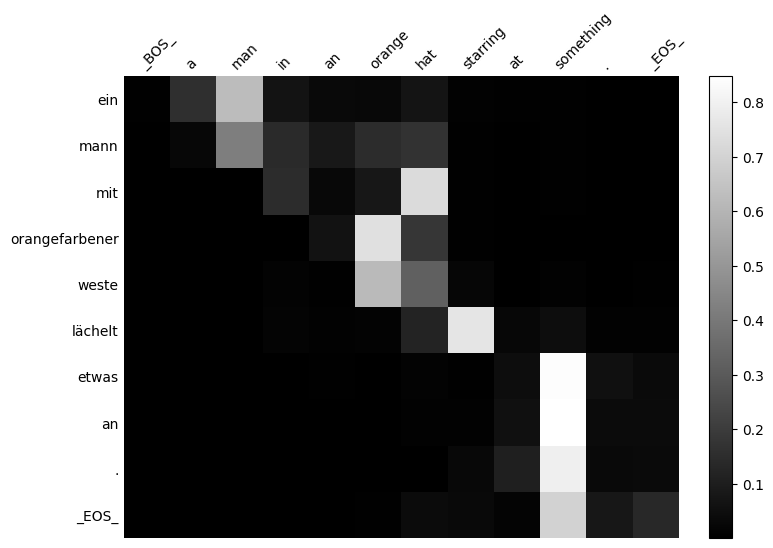

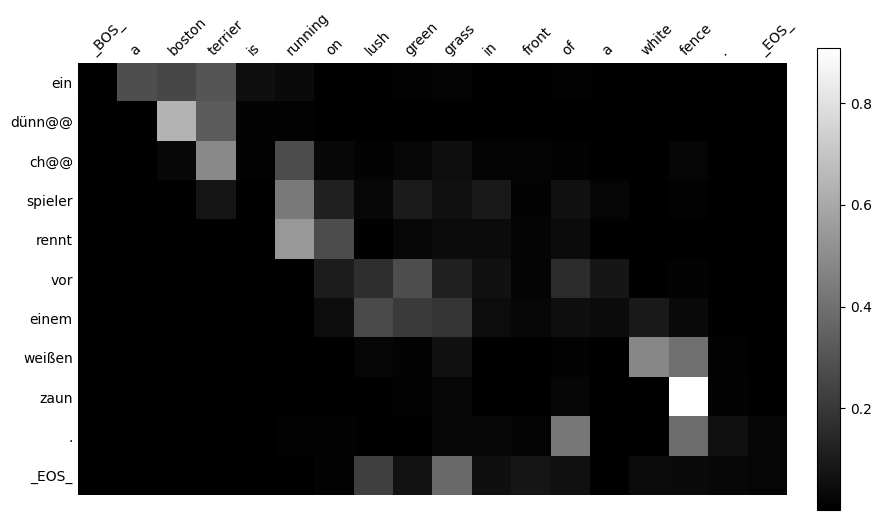

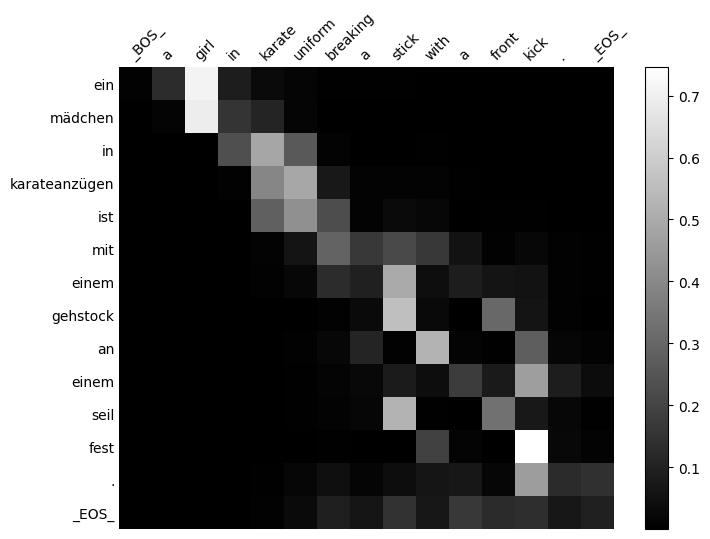

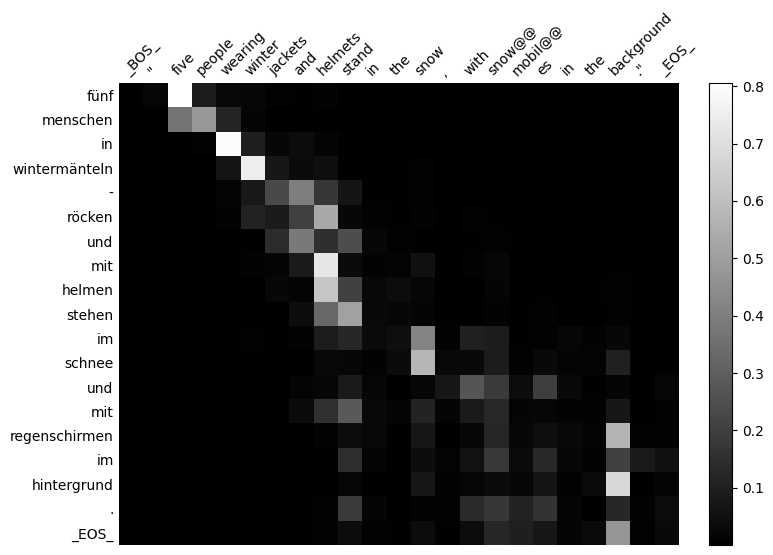

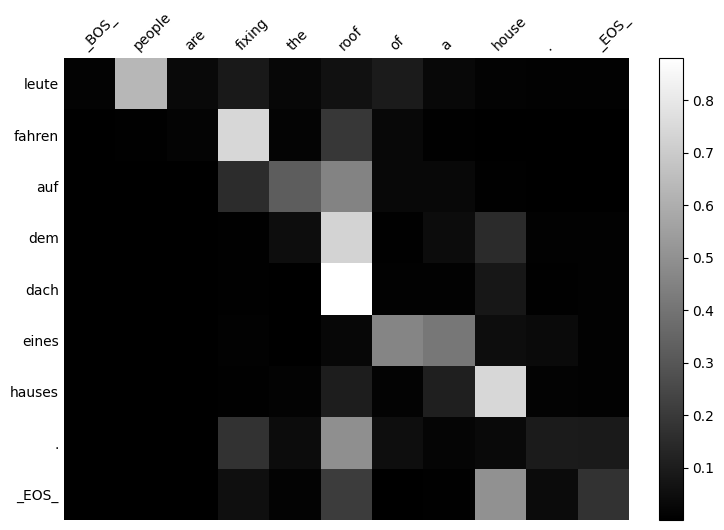

In [38]:
for i in range(5):
    draw_attention(test_inp[i], trans[i], attention_probs[i])

### How attention explains two of the errors

In the first attention map, the output token "weste" (vest) places its strongest attention weight on the source token "orange" rather than on "hat". Since "orange" was the dominant attended token in that region of the input, the decoder used a different garment word ("weste") that co-occurs with "orange" in training data, rather than the correct "hut" (hat). The attention map shows that the error is not a failure to look at the right neighborhood in the input but a failure to attend to the precise token that carries the meaning.

In the fifth attention map, the output token "fahren" (to drive) has its highest attention weight on "fixing" in the source sentence. The model is looking at the right source word but still produces the wrong German verb. This suggests the error is not a misalignment issue but a lexical confusion in the decoder. "fixing" is rare in the training data and the model learned to associate that source region with motion verbs like "fahren" that appeared in structurally similar sentences. The rest of the sentence "auf dem dach eines hauses" (on the roof of a house) is translated correctly with diagonal attention, which means that the single misattended verb is the sole source of the semantic distortion.

### Patterns in high-attention token pairs

Some cells in the attention maps have very large weights. To find patterns, I extract every source–target token pair above a threshold across the first 50 test sentences, using a provided helper function.

In [39]:
def print_attention_weights_for_sentence(sentence, model, inp_voc, out_voc, threshold=0.7):
    """
    Given an input sentence, translates it using the model,
    then prints all source-token to target-token attention weights.
    """
    # Translate sentence and get states
    translation, states = model.translate_lines([sentence])
    attention_probs = np.stack([state[-1].detach().cpu().numpy() for state in states], axis=1)
    # Compatible with both probs shape [batch, ninp] and squeezed [ninp]
    if attention_probs.ndim == 3:
        probs = attention_probs[0, :, :]
    elif attention_probs.ndim == 2:
        probs = attention_probs.T
    else:
        raise ValueError(f"Unexpected attention_probs shape: {attention_probs.shape}")

    inp_tokens = inp_voc.tokenize(sentence)
    trans_tokens = out_voc.tokenize(translation[0])[1:]
    # Match probabilities to the valid length (can be shorter due to eos)
    probs = probs[:len(trans_tokens), :len(inp_tokens)]
    # print(f"Input: {sentence}")
    # print(f"Translation: {translation[0]}")
    for out_idx, out_tok in enumerate(trans_tokens):
        for in_idx, in_tok in enumerate(inp_tokens):
            if probs[out_idx, in_idx] >= threshold:
                print(f"  {out_tok} <--{probs[out_idx, in_idx]:.2f}-- {in_tok}")

#### Pairs with attention ≥ 0.7

*What recurring patterns appear?*

In [44]:
for i in range(50):
    print_attention_weights_for_sentence(test_inp[i], model, inp_voc, out_voc, threshold=0.7)

  mit <--0.73-- hat
  orangefarbener <--0.74-- orange
  lächelt <--0.76-- starring
  etwas <--0.84-- something
  an <--0.85-- something
  . <--0.79-- something
  zaun <--0.91-- fence
  ein <--0.71-- girl
  fest <--0.75-- kick
  fünf <--0.81-- five
  in <--0.79-- wearing
  wintermänteln <--0.75-- winter
  mit <--0.73-- helmets
  fahren <--0.74-- fixing
  dem <--0.73-- roof
  dach <--0.88-- roof
  hauses <--0.74-- house
  einer <--0.77-- group
  gruppe <--0.81-- group
  unaufgeräumten <--0.88-- str@@
  steht <--0.85-- standing
  schaufenster <--0.72-- i@@
  trikot <--0.72-- uniform
  ein <--0.75-- guy
  arbeitet <--0.76-- works
  gebäude <--0.95-- building
  . <--0.72-- works
  weste <--0.75-- vest
  hält <--0.79-- holding
  zeitschriften <--0.76-- magazines
  . <--0.73-- magazines
  eine <--0.81-- mother
  mutter <--0.72-- mother
  und <--0.94-- and
  ihre <--0.84-- her
  wunderschönen <--0.93-- beautiful
  " <--0.71-- men
  volleyball <--0.82-- volleyball
  einer <--0.74-- one
  luft <

One recurring pattern is that German articles and determiners (ein, eine, einer, einem) receive high attention to nearby English nouns rather than English articles. For example, `ein <--0.75-- guy`, `ein <--0.75-- girl`, `einer <--0.76-- kitchen`. This happens because German determiner choice depends on gender, number, and case. To choose the correct German determiner form, the decoder needs context from the noun phrase, so attention shifts to the content noun.

A second pattern is strong one-to-one alignment for concrete content words, especially nouns and verbs: `gebäude <--0.95-- building`, `dach <--0.88-- roof`, `kind <--0.90-- kid`, `schneidet <--0.97-- cutting`, and `kocht <--0.94-- cooking`. These pairs get high attention because they are semantically specific and usually have a dominant translation equivalent in the training data. Because of that, the model can place a large fraction of probability mass on a single source token. This pattern is useful analytically because it shows that the model’s attention is structured and not random.

#### Pairs with attention ≥ 0.9

*Which patterns shrink or disappear at the stricter threshold, and why?*

In [43]:
for i in range(50):
    print_attention_weights_for_sentence(test_inp[i], model, inp_voc, out_voc, threshold=0.9)

  zaun <--0.91-- fence
  gebäude <--0.95-- building
  und <--0.94-- and
  wunderschönen <--0.93-- beautiful
  küche <--0.93-- kitchen
  ein <--0.92-- man
  vollen <--0.93-- cave
  steht <--0.96-- standing
  helfen <--0.90-- pre@@
  gebäude <--0.91-- building
  mit <--0.90-- her
  pullover <--0.91-- sweater
  schneidet <--0.97-- cutting
  fahren <--0.95-- ride
  sitzen <--0.92-- sitting
  hand@@ <--0.99-- pizza
  hemd <--0.95-- shirt
  lkw <--0.95-- truck
  zug <--0.92-- train
  luft <--0.96-- forest
  luft <--0.91-- forest
  hemd <--0.98-- shirt
  einen <--0.96-- an
  bereitet <--0.95-- cooking
  kocht <--0.94-- cooking
  essen <--0.92-- food
  . <--0.98-- stove


When using 0.9 as the threshold, the determiner pairs (ein, eine, einer, einem) mostly disappear, with only `ein <--0.92-- man` staying (other than `einen <--0.96-- an`, the true translation). This is because generating the correct German article requires attending to the gender, case, and surrounding structure so the model's attention is distributed across multiple tokens instead of one. Also, the model sometimes picks the wrong gender form because the distributed attention does not perfectly capture agreement.

However, the second pattern with the correct translation of nouns remains. These are unambiguous one-to-one lexical mappings where no contextual disambiguation is needed, so the model can confidently concentrate nearly all its probability mass on a single source token. The difference between the two patterns at 0.9 shows a distinction in how the model uses attention. For morphologically dependent function words it uses attention as soft aggregation over context and for concrete lexical items it uses attention as a hard selector.